# 42d · Project: a quadruped that trots, with no learning at all (Unitree Go2)
Before RL locomotion (S05 53), legged robots walked with hand-built controllers, and many still do. This project
builds one from scratch for the Unitree Go2 (Menagerie), whose motors take raw torque:

```
command (vx, vy, yaw rate) ─▶ gait clock (trot: diagonal pairs) ─▶ foot trajectories (swing / stance)
       ─▶ Raibert foot placement ─▶ leg inverse kinematics ─▶ joint PD + gravity feed-forward ─▶ 12 torques
```
Every layer is measured: what gravity feed-forward fixes, how well speed is tracked, what foot placement buys
against pushes, and a figure-8 walked with a path follower.

In [1]:
import numpy as np, matplotlib.pyplot as plt, mujoco
from vlacourse import show_video
from vlacourse import showcase as sc
from vlacourse.quadruped import Go2World, Go2Trot, Follow, leg_ik, L1, L2, L3

## 1. Leg inverse kinematics
Each leg: hip roll (about x), thigh and calf (about y), thigh and calf both 0.213 m. Closed form: the roll angle puts
the foot in the leg's plane, then a 2-link planar IK (law of cosines) gives thigh and calf; the knee bends backwards.

In [2]:
q = leg_ik(np.array([0.0, L1, -0.2648]), +1)
print("IK of the standing foot position:", q.round(3), "(the 'home' keyframe is 0, 0.9, -1.8)")

IK of the standing foot position: [ 0.   0.9 -1.8] (the 'home' keyframe is 0, 0.9, -1.8)


## 2. What gravity feed-forward fixes
Joint PD alone sags under the robot's 15 kg, and with knees that bend backwards a sagging leg also shifts the foot:
the robot drifts backwards even when told to stand still. Feed-forward: each stance foot pushes down with its share
of the weight, $\tau = J^\top F$ with $F = (0, 0, -mg/n_\text{stance})$.

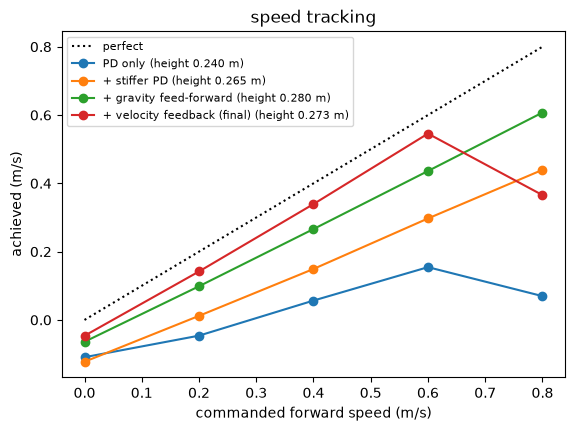

In [3]:
def track(vx, **kw):
    w = Go2World(); c = Go2Trot(**kw); vs, zs = [], []
    def cmd(t):
        if t >= 6: return None
        if t > 2: vs.append(w.base()["vel_body"][0]); zs.append(w.base()["pos"][2])
        return (vx, 0.0, 0.0)
    ok = c.run(w, cmd)
    return np.mean(vs), np.mean(zs), ok

speeds = np.array([0.0, 0.2, 0.4, 0.6, 0.8])
res = {name: [track(v, **kw) for v in speeds] for name, kw in [("PD only", dict(gravity_ff=False, k_vel=0.0, kp=60.0)),
                                                                ("+ stiffer PD", dict(gravity_ff=False, k_vel=0.0)),
                                                                ("+ gravity feed-forward", dict(k_vel=0.0)),
                                                                ("+ velocity feedback (final)", dict())]}
plt.figure(figsize=(6.5, 4.5)); plt.plot(speeds, speeds, "k:", label="perfect")
for name, r in res.items():
    plt.plot(speeds, [x[0] for x in r], "o-", label=f"{name} (height {np.mean([x[1] for x in r]):.3f} m)")
plt.xlabel("commanded forward speed (m/s)"); plt.ylabel("achieved (m/s)"); plt.legend(fontsize=8); plt.title("speed tracking"); plt.show()

## 3. Raibert foot placement against pushes
Marc Raibert's rule (1986): land the swing foot where it catches the drift, $p = p_\text{hip} + v\,T_\text{st}/2 + k\,(v - v_\text{cmd})$.
A shove sideways makes the next steps land further out, and the robot "walks it off". Trotting at 0.3 m/s,
a 0.1 s sideways push of increasing force:

In [4]:
forces = [20, 40, 60, 80, 100, 130, 160, 200]
surv = {}
for name, kw in [("no foot placement", dict(raibert=False)), ("Raibert k = 0.08", dict(k_raibert=0.08)), ("Raibert k = 0.2 (final)", dict(k_raibert=0.2))]:
    surv[name] = []
    for F in forces:
        w = Go2World(); c = Go2Trot(**kw)
        surv[name].append(c.run(w, lambda t: (0.3, 0, 0) if t < 5 else None, push_fn=lambda t, F=F: np.array([0, F, 0]) if 2.0 <= t < 2.1 else None))
    print(f"{name:24s} survived: " + " ".join(f"{F}N:{'✓' if s else '✗'}" for F, s in zip(forces, surv[name])))

no foot placement        survived: 20N:✓ 40N:✓ 60N:✓ 80N:✓ 100N:✗ 130N:✗ 160N:✗ 200N:✗


Raibert k = 0.08         survived: 20N:✓ 40N:✓ 60N:✓ 80N:✓ 100N:✓ 130N:✗ 160N:✗ 200N:✗


Raibert k = 0.2 (final)  survived: 20N:✓ 40N:✓ 60N:✓ 80N:✓ 100N:✓ 130N:✓ 160N:✓ 200N:✗


## 4. A figure-8 with a path follower
Commands come from a pure-pursuit follower: aim at a point 35 cm ahead on the path; yaw rate ∝ heading error;
slow down in sharp turns. The path is a lemniscate (figure-8).

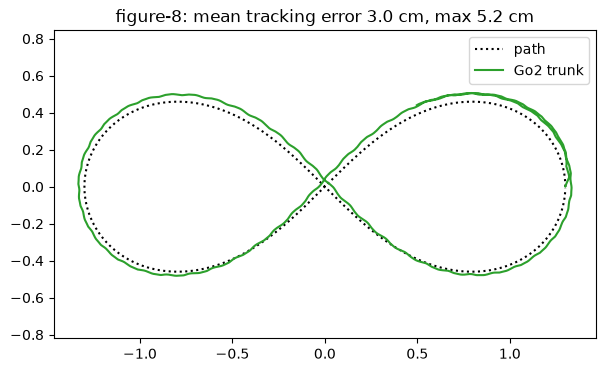

completed without falling: True


In [5]:
def lemniscate(a=1.3, n=800):
    t = np.linspace(0, 2 * np.pi, n, endpoint=False); s, c = np.sin(t), np.cos(t)
    return np.c_[a * c / (1 + s ** 2), a * s * c / (1 + s ** 2)]

class Follower:
    def __init__(self, path, v=0.4, look=0.35, k_yaw=1.8):
        self.p, self.v, self.look, self.k, self.i = path, v, look, k_yaw, 0
    def __call__(self, b):
        pos, yaw = b["pos"][:2], b["rpy"][2]
        d = np.linalg.norm(self.p - pos, axis=1)
        self.i = (self.i + int(np.argmin(np.r_[d[self.i:], d[:self.i]][:80]))) % len(self.p)
        j = self.i
        while np.linalg.norm(self.p[j % len(self.p)] - pos) < self.look:
            j += 1
        err = (np.arctan2(*(self.p[j % len(self.p)] - pos)[::-1]) - yaw + np.pi) % (2 * np.pi) - np.pi
        return (self.v * max(0.2, np.cos(err)), 0.0, float(np.clip(self.k * err, -1.0, 1.0))), d.min()

P = lemniscate()
def walk_figure8(seconds=26.0, film=None):
    w = Go2World(); c = Go2Trot(); f = Follower(P)
    w.d.qpos[:2] = P[0]; y0 = np.arctan2(*(P[5] - P[0])[::-1]); w.d.qpos[3:7] = [np.cos(y0 / 2), 0, 0, np.sin(y0 / 2)]; mujoco.mj_forward(w.m, w.d)
    errs, path, frames = [], [], []
    fol = (Follow(w, size=(720, 640)), TopView(w)) if film else None
    def cmd(t):
        if t > seconds: return None
        u, e = f(w.base()); errs.append(e); path.append(w.base()["pos"][:2].copy()); return u
    tick = None if not film else (lambda world, k: frames.append(film(world, fol)) if k % 10 == 0 else None)
    ok = c.run(w, cmd, on_tick=tick)
    return ok, np.array(errs), np.array(path), frames

ok, errs, path, _ = walk_figure8()
plt.figure(figsize=(7, 4)); plt.plot(P[:, 0], P[:, 1], "k:", label="path"); plt.plot(path[:, 0], path[:, 1], c="tab:green", label="Go2 trunk")
plt.axis("equal"); plt.legend(); plt.title(f"figure-8: mean tracking error {100 * errs.mean():.1f} cm, max {100 * errs.max():.1f} cm"); plt.show()
print("completed without falling:", ok)

## 5. Share-ready video

In [6]:
class TopView:
    """A camera straight above the figure-8 that draws the planned path (white) and the trunk's trail (green)."""
    def __init__(self, world, size=(720, 640)):
        self.w, self.r, self.trail = world, mujoco.Renderer(world.m, *size), []
        self.cam = mujoco.MjvCamera(); self.cam.lookat[:] = [P[:, 0].mean(), P[:, 1].mean(), 0]
        self.cam.distance, self.cam.elevation, self.cam.azimuth = 5.4, -89.9, 90
    def _line(self, a, b, width, rgba):
        sc_ = self.r.scene
        if sc_.ngeom < sc_.maxgeom:
            g = sc_.geoms[sc_.ngeom]
            mujoco.mjv_initGeom(g, mujoco.mjtGeom.mjGEOM_CAPSULE, np.zeros(3), np.zeros(3), np.zeros(9), np.asarray(rgba, np.float32))
            mujoco.mjv_connector(g, mujoco.mjtGeom.mjGEOM_CAPSULE, width, a, b); sc_.ngeom += 1
    def render(self):
        self.trail.append(np.r_[self.w.base()["pos"][:2], 0.012])
        self.r.update_scene(self.w.d, self.cam)
        for k in range(0, len(P), 8):                                   # the planned path
            a, b = P[k], P[(k + 8) % len(P)]
            self._line(np.r_[a, 0.006], np.r_[b, 0.006], 0.008, [1, 1, 1, 0.8])
        for k in range(1, len(self.trail), 2):                          # where the trunk actually went
            self._line(self.trail[k - 1], self.trail[k], 0.014, [0.2, 0.95, 0.45, 1])
        return self.r.render().copy()

def fig8_frame(world, cams):
    fol, top = cams
    left = sc.caption(fol.render(), "Go2 trot · following a figure-8", where="top", size=22)
    right = sc.caption(top.render(), "top view: path (white) and trail (green)", where="top", size=22)
    right = sc.badge(right, f"t = {world.t:4.1f} s · v = {world.base()['vel_body'][0]:.2f} m/s", corner="br", size=18)
    return np.hstack([left, right])

_, _, _, frames8 = walk_figure8(seconds=24.0, film=fig8_frame)

push_clips = {}
for name, kw in [("no foot placement", dict(raibert=False)), ("Raibert foot placement", dict())]:
    w = Go2World(); fol = Follow(w, size=(720, 640)); fr = []; F = 120.0
    def tick(world, k, name=name):
        if k % 10 == 0:
            pushing = 2.0 <= world.t < 2.1
            img = fol.render(np.array([0, 1.0, 0]) if pushing else None)
            img = sc.caption(img, name, where="top", size=22)
            fr.append(sc.badge(img, f"push {F:.0f} N" if pushing else f"t = {world.t:.1f} s", corner="tr", size=18, color=sc.BAD if pushing else sc.ACCENT))
    ok = Go2Trot(**kw).run(w, lambda t: (0.3, 0, 0) if t < 5 else None, push_fn=lambda t: np.array([0, F, 0]) if 2.0 <= t < 2.1 else None, on_tick=tick)
    push_clips[name] = fr + [sc.badge(fr[-1], "✓ walked it off" if ok else "✗ fell", corner="bl", size=26, color=sc.GOOD if ok else sc.BAD)] * 40
T = max(len(c) for c in push_clips.values())
side = [np.hstack([c[min(t, len(c) - 1)] for c in push_clips.values()]) for t in range(T)]
video = sc.title_card("A quadruped trot, no learning", "gait clock · Raibert foot placement · leg IK · joint PD\nMuJoCo · Unitree Go2 (Menagerie)", size=(720, 1280), n=60) + frames8 + side
show_video(video, fps=50, title="42d Go2 trot HD", width=960)
sc.export(video, "outputs/42d_go2_trot.mp4", fps=50)

saved outputs/42d_go2_trot.mp4  (30.2 MB)


['outputs/42d_go2_trot.mp4']

## Exercises
1. **Other gaits:** change the pairing to a pace (left legs together) and a bound (front pair, rear pair). Which is
   most stable at 0.6 m/s? Why do animals switch gaits with speed?
2. **Faster:** shorten the period to 0.3 s and raise the step height. What limits top speed now?
3. **Rough ground:** add random boxes to the floor. Which layer has to change, and which can stay?
4. **Compare with RL:** S05 53 trains a Go1 to walk with PPO in 25 minutes. List three things the learned policy
   handles that this controller doesn't, and one thing this controller guarantees that the RL policy doesn't.